# NN_L14_zeroshot_prompts

**Zero-shot accuracy of CLIP ViT-B/32 and ViT-B/16 on 5,400 EuroSAT test images for four prompt designs: folder name, 'a photo of', 'a satellite photo of' and an ensemble of five satellite templates.**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_zeroshot_prompts/NN_L14_zeroshot_prompts.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

zero-shot accuracy B32, name (%) = 34.1   [zs.B32_name]
zero-shot accuracy B32, photo (%) = 42.7   [zs.B32_photo]
zero-shot accuracy B32, sat (%) = 44.9   [zs.B32_sat]
zero-shot accuracy B32, ens (%) = 49.1   [zs.B32_ens]
zero-shot accuracy B16, name (%) = 42.4   [zs.B16_name]
zero-shot accuracy B16, photo (%) = 46.7   [zs.B16_photo]
zero-shot accuracy B16, sat (%) = 55.4   [zs.B16_sat]
zero-shot accuracy B16, ens (%) = 56.4   [zs.B16_ens]


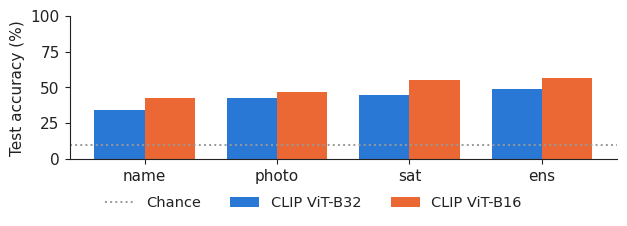

In [3]:
RES = REPO + 'lectures/L14/results/'
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
T = ['name', 'photo', 'sat', 'ens']
acc = {}
for k in ('B32', 'B16'):
    for t in T:
        acc[(k, t)] = round(100 * float((Z[f'{k}_{t}'] == Z['true']).mean()), 1)
        show(f'zs.{k}_{t}', f'zero-shot accuracy {k}, {t} (%)', acc[(k, t)])
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for j, (k, c) in enumerate((('B32', PAL['data']), ('B16', PAL['model']))):
    ax.bar(np.arange(4) + (j - 0.5) * 0.38, [acc[(k, t)] for t in T], 0.38, color=c, label='CLIP ViT-' + k)
ax.axhline(10, ls=':', color='#999999', label='Chance')
ax.set_xticks(range(4))
ax.set_xticklabels(T)
ax.set_ylabel('Test accuracy (%)')
ax.set_ylim(0, 100)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('zeroshot_prompts.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()